<FONT SIZE=6 COLOR="orange">Dataset Loading and Initial Inspection ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section loads the updated Mexico respiratory surveillance dataset, dated May 18, 2026, and performs an initial inspection of its structure, dimensions, variables, and missing or special coded values before any preprocessing or analytical transformations are applied.
</FONT>

<FONT SIZE=6 COLOR="orange">Mount Google Drive ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section connects Google Colab to Google Drive so the dataset can be accessed directly from the project folder.
</FONT>

In [ ]:
# Import the Google Drive module for Colab ✔
from google.colab import drive

# Mount Google Drive to access project files
drive.mount('/content/drive')

Mounted at /content/drive


<FONT SIZE=6 COLOR="orange">Import Required Libraries ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section imports the libraries required for data manipulation, visualization, statistical analysis, and predictive modeling throughout the capstone project.
</FONT>

In [ ]:
# Numerical computing library ✔
import numpy as np

# Data manipulation and analysis library
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis functions
from scipy import stats

from sklearn.ensemble import RandomForestClassifier

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

# Configure visual style for plots
sns.set_style("whitegrid")

# Display plots inline in Colab
%matplotlib inline

<FONT SIZE=6 COLOR="orange">Importing the Updated Dataset ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section loads the updated Mexican respiratory surveillance dataset, dated May 18, 2026, into a pandas DataFrame for initial inspection, preprocessing, and subsequent analytical modeling.
</FONT>

In [ ]:
# Define the updated dataset file path from Google Drive
path="/content/drive/MyDrive/MsMLAI/Parte4/COVID19MEXICO.csv"

# Load the updated CSV dataset into a pandas DataFrame
df = pd.read_csv(path)

# Display the first rows of the dataset
df.head()

,FECHA_ACTUALIZACION,ID_REGISTRO,ORIGEN,SECTOR,ENTIDAD_UM,SEXO,ENTIDAD_NAC,ENTIDAD_RES,MUNICIPIO_RES,TIPO_PACIENTE,...,RESULTADO_PCR,RESULTADO_PCR_COINFECCION,TOMA_MUESTRA_ANTIGENO,RESULTADO_ANTIGENO,CLASIFICACION_FINAL_COVID,CLASIFICACION_FINAL_FLU,MIGRANTE,PAIS_NACIONALIDAD,PAIS_ORIGEN,UCI
0,18/05/2026,28856,1,12,14,2,15,9,14,1,...,999,999,2,97,6,6,99,México,97,97
1,18/05/2026,167f1a,1,12,1,2,1,1,3,1,...,997,997,2,97,6,6,99,México,97,97
2,18/05/2026,109fd5,1,12,1,1,1,1,1,2,...,5,5,2,97,7,7,99,México,97,2
3,18/05/2026,g8911c0,1,13,19,2,19,19,48,1,...,997,997,2,97,6,6,99,México,97,97
4,18/05/2026,g5963e1,1,12,9,1,9,9,13,1,...,5,5,2,97,7,7,99,México,97,97


<FONT SIZE=6 COLOR="orange">Initial Dataset Inspection ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section examines the updated dataset structure, including the total number of observations and variables, column names, data types, and the presence of missing or special coded values prior to preprocessing and analytical modeling.
</FONT>

In [ ]:
# Display the number of rows and columns in the updated dataset
print("Updated Dataset Shape:")
print(df.shape)

# Display column names and data types
print("\nDataset Information:")
df.info()

# Display the number of standard missing values per column
print("\nMissing Values by Column:")
print(df.isna().sum())

# Display frequency counts for common special coded values
print("\nSpecial Coded Values Check:")
special_codes = [97, 98, 99, 997, 999]

for code in special_codes:
    total_count = (df == code).sum().sum()
    print(f"Code {code}: {total_count} occurrences")

Updated Dataset Shape:
(219023, 42)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 219023 entries, 0 to 219022
Data columns (total 42 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   FECHA_ACTUALIZACION        219023 non-null  object
 1   ID_REGISTRO                219023 non-null  object
 2   ORIGEN                     219023 non-null  int64 
 3   SECTOR                     219023 non-null  int64 
 4   ENTIDAD_UM                 219023 non-null  int64 
 5   SEXO                       219023 non-null  int64 
 6   ENTIDAD_NAC                219023 non-null  int64 
 7   ENTIDAD_RES                219023 non-null  int64 
 8   MUNICIPIO_RES              219023 non-null  int64 
 9   TIPO_PACIENTE              219023 non-null  int64 
 10  FECHA_INGRESO              219023 non-null  object
 11  FECHA_SINTOMAS             219023 non-null  object
 12  FECHA_DEF                  219023 non-null

<FONT SIZE=6 COLOR="orange">Special Codes and Value Distribution Review ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section reviews the unique values and frequency distributions of key categorical variables to identify special codes, non-informative values, and recoding needs before data cleaning.
</FONT>

In [ ]:
# Define key variables for the capstone analysis
key_variables = [
    "TIPO_PACIENTE",
    "SEXO",
    "NEUMONIA",
    "DIABETES",
    "EPOC",
    "ASMA",
    "INMUSUPR",
    "HIPERTENSION",
    "CARDIOVASCULAR",
    "OBESIDAD",
    "RENAL_CRONICA",
    "TABAQUISMO",
    "INTUBADO",
    "UCI"
]

# Loop through each key variable
for col in key_variables:

    # Print the column name
    print(f"\n--- {col} ---")

    # Print the frequency of each coded value
    print(df[col].value_counts(dropna=False).sort_index())

    # Identify common special coded values
    special_counts = df[col].isin([97, 98, 99]).sum()

    # Print total number of special coded values
    print(f"Special coded values (97, 98, 99): {special_counts}")


--- TIPO_PACIENTE ---
TIPO_PACIENTE
1    114740
2    104283
Name: count, dtype: int64
Special coded values (97, 98, 99): 0

--- SEXO ---
SEXO
1    120843
2     98180
Name: count, dtype: int64
Special coded values (97, 98, 99): 0

--- NEUMONIA ---
NEUMONIA
1     54734
2    164289
Name: count, dtype: int64
Special coded values (97, 98, 99): 0

--- DIABETES ---
DIABETES
1      28727
2     190020
98       276
Name: count, dtype: int64
Special coded values (97, 98, 99): 276

--- EPOC ---
EPOC
1       7525
2     211214
98       284
Name: count, dtype: int64
Special coded values (97, 98, 99): 284

--- ASMA ---
ASMA
1       8976
2     209759
98       288
Name: count, dtype: int64
Special coded values (97, 98, 99): 288

--- INMUSUPR ---
INMUSUPR
1       6877
2     211938
98       208
Name: count, dtype: int64
Special coded values (97, 98, 99): 208

--- HIPERTENSION ---
HIPERTENSION
1      34749
2     184065
98       209
Name: count, dtype: int64
Special coded values (97, 98, 99): 209

--- CARD

<FONT SIZE=6 COLOR="orange">Exploratory Data Analysis (EDA) ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section performs an initial exploratory analysis of the respiratory surveillance dataset, focusing on hospitalization distribution, demographic patterns, and age characteristics before predictive modeling.
</FONT>


Hospitalization Distribution:
TIPO_PACIENTE
1    114740
2    104283
Name: count, dtype: int64

Hospitalization Percentage Distribution:
TIPO_PACIENTE
1    52.387192
2    47.612808
Name: proportion, dtype: float64

Age Descriptive Statistics:
count    219023.000000
mean         35.122795
std          26.421997
min           0.000000
25%          10.000000
50%          32.000000
75%          56.000000
max         121.000000
Name: EDAD, dtype: float64


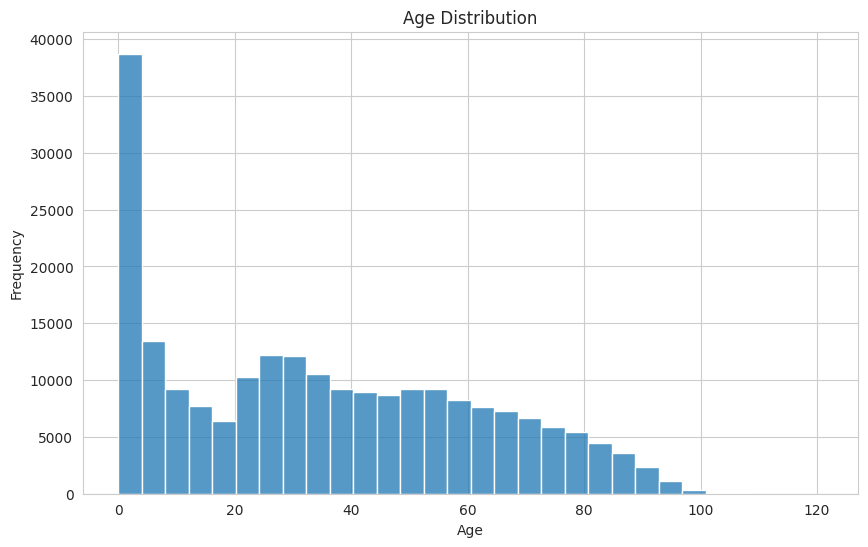

In [ ]:
# Display hospitalization distribution ✔
print("\nHospitalization Distribution:")
print(df["TIPO_PACIENTE"].value_counts())

# Display normalized hospitalization percentages
print("\nHospitalization Percentage Distribution:")
print(df["TIPO_PACIENTE"].value_counts(normalize=True) * 100)

# Generate descriptive statistics for age
print("\nAge Descriptive Statistics:")
print(df["EDAD"].describe())

# Create histogram for age distribution
plt.figure(figsize=(10,6))

# Plot age histogram
sns.histplot(df["EDAD"], bins=30)

# Add title and labels
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

# Show the plot
plt.show()

<FONT SIZE=5 COLOR="F6B1F0"><b> Nota mental:</b>
<br>
“The hospitalization outcome was relatively balanced, suggesting that low recall in the baseline model is not primarily driven by severe class imbalance. The age distribution was non-normal, with strong representation of younger patients and broad coverage across adult and older age groups.”</FONT>

<FONT SIZE=6 COLOR="orange">Hospitalization and Demographic Analysis ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section explores the relationship between hospitalization status and key demographic variables, including sex and age, in order to support Research Question 1 (RQ1).
</FONT>


Sex vs Hospitalization:
TIPO_PACIENTE      1      2
SEXO                       
1              69876  50967
2              44864  53316

Sex vs Hospitalization - Row Percentages:
TIPO_PACIENTE          1          2
SEXO                               
1              57.823788  42.176212
2              45.695661  54.304339

Chi-square Test Results:
Chi-square statistic: 3193.9436
P-value: 0.0000000000
Degrees of freedom: 1


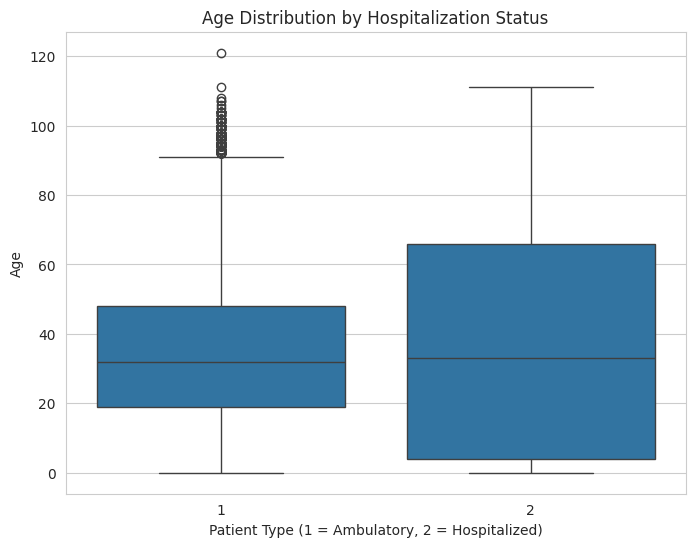

In [ ]:
# Create a cross-tabulation between sex and hospitalization status
sex_hosp_table = pd.crosstab(df["SEXO"], df["TIPO_PACIENTE"])

# Display the contingency table
print("\nSex vs Hospitalization:")
print(sex_hosp_table)

# Display row percentages to interpret hospitalization distribution by sex
print("\nSex vs Hospitalization - Row Percentages:")
print(pd.crosstab(df["SEXO"], df["TIPO_PACIENTE"], normalize="index") * 100)

# Perform chi-square test of independence
chi2, p, dof, expected = stats.chi2_contingency(sex_hosp_table)

# Display chi-square test results
print("\nChi-square Test Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p:.10f}")
print(f"Degrees of freedom: {dof}")

# Create boxplot for age by hospitalization status
plt.figure(figsize=(8,6))

# Generate boxplot
sns.boxplot(x="TIPO_PACIENTE", y="EDAD", data=df)

# Add labels and title
plt.title("Age Distribution by Hospitalization Status")
plt.xlabel("Patient Type (1 = Ambulatory, 2 = Hospitalized)")
plt.ylabel("Age")

# Show plot
plt.show()

<FONT SIZE=5 COLOR="F6B1F0"><b>Note:</b> <br>
This figure supports the exploratory characterization of the analytical dataset by comparing age distribution according to hospitalization status. <br><br>
Although the overall dataset includes a substantial number of young patients, hospitalized patients show a broader age distribution and greater representation in older age ranges compared with ambulatory patients. This pattern suggests that age contributes to the clinical and epidemiological profile associated with hospitalization status. <br><br>
In the context of the article, age is not interpreted as an isolated determinant of hospitalization. Instead, it is considered as a contextual variable that helps characterize baseline differences between ambulatory and hospitalized patients within the broader hospitalization risk stratification workflow. </FONT>


<FONT SIZE=6 COLOR="orange">Comorbidities and Hospitalization Analysis ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section evaluates the relationship between selected comorbidities and hospitalization status in order to support Research Question 2 (RQ2).
</FONT>

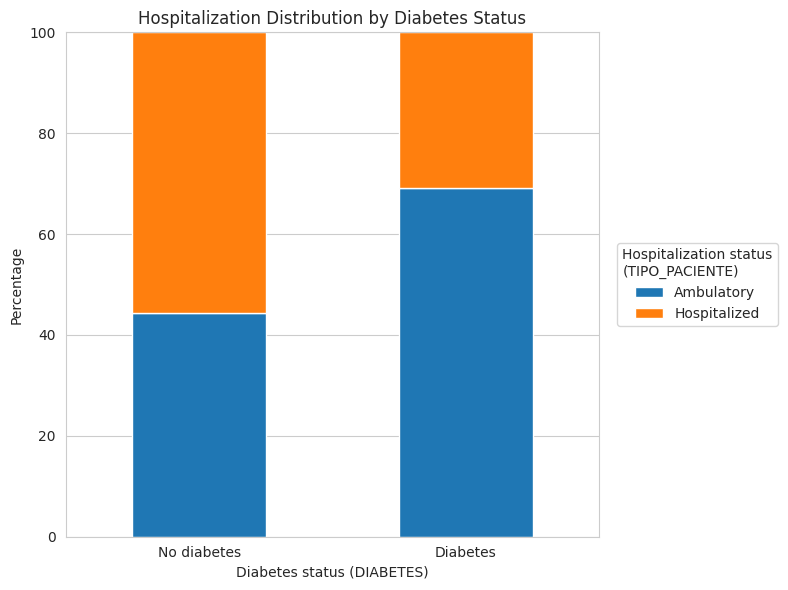

In [ ]:
# Define comorbidity variables for analysis ✔
comorbidities = [
    "DIABETES",
    "HIPERTENSION",
    "OBESIDAD",
    "EPOC"
]

# Create hospitalization percentage plot for diabetes after excluding special codes
diabetes_plot = pd.crosstab(
    eda_comorbidity_df["DIABETES"],
    eda_comorbidity_df["TIPO_PACIENTE"],
    normalize="index"
) * 100

# Rename diabetes categories
# Works whether DIABETES is coded as 0/1 or 1/2
diabetes_plot = diabetes_plot.rename(index={
    0: "No diabetes",
    1: "Diabetes",
    2: "No diabetes"
})

# Rename hospitalization categories
# Works whether TIPO_PACIENTE is coded as 0/1 or 1/2
diabetes_plot = diabetes_plot.rename(columns={
    0: "Ambulatory",
    1: "Hospitalized",
    2: "Ambulatory"
})

# Force the correct order on the x-axis
diabetes_plot = diabetes_plot.loc[["No diabetes", "Diabetes"]]

# Force the correct order in the stacked bars
diabetes_plot = diabetes_plot[["Ambulatory", "Hospitalized"]]

# Generate stacked bar plot
ax = diabetes_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 6)
)

# Add labels and title
plt.title("Hospitalization Distribution by Diabetes Status")
plt.xlabel("Diabetes status (DIABETES)")
plt.ylabel("Percentage")
plt.ylim(0, 100)

# Keep x labels horizontal
plt.xticks(rotation=0)

# Improve legend
plt.legend(
    title="Hospitalization status\n(TIPO_PACIENTE)",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "Figure_4_Hospitalization_Distribution_by_Diabetes_Status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<FONT SIZE=5 COLOR="F6B1F0"><b>Note: ✔</b> <br>
After excluding special coded values such as 97, 98, and 99 when applicable, the exploratory comorbidity analysis showed clear and statistically significant associations with hospitalization status. <br><br>
Patients with diabetes, hypertension, obesity, and COPD showed higher hospitalization proportions than patients without these conditions. Among the comorbidities evaluated, COPD presented the strongest descriptive pattern, with approximately 87.9% of patients with COPD hospitalized, compared with 46.2% among patients without COPD. <br><br>
Diabetes and hypertension also showed relevant hospitalization patterns: 69.1% of patients with diabetes and 67.1% of patients with hypertension were hospitalized. These findings support the inclusion of comorbidities as clinically meaningful predictors in the hospitalization risk stratification workflow. <br><br> <b>Key interpretation:</b> <br>
• Diabetes: 69.1% hospitalization among patients with diabetes vs. 44.4% among patients without diabetes. <br>
• Hypertension: 67.1% hospitalization among patients with hypertension vs. 43.9% among patients without hypertension. <br>
• Obesity: weaker association compared with diabetes, hypertension, and COPD, but still statistically significant. <br>
• COPD: strongest descriptive comorbidity pattern, with 87.9% hospitalization among patients with COPD vs. 46.2% among patients without COPD. <br><br>
This visualization supports the article’s methodological argument: open respiratory surveillance data can be transformed into interpretable hospitalization risk indicators when special coded values are handled carefully and clinical variables are analyzed within a reproducible workflow. <br><br>
The diabetes figure is therefore more defensible because it no longer treats operational surveillance codes as valid clinical categories. The original variable names, such as <b>DIABETES</b> and <b>TIPO_PACIENTE</b>, are preserved for traceability with the official data dictionary. </FONT>


<FONT SIZE=6 COLOR="orange">Data Cleaning and Recoding ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section performs basic data cleaning and recoding procedures required for statistical analysis and predictive modeling. Special coded values representing unknown, missing, or non-applicable information are converted into missing values (NaN) to improve analytical consistency.
</FONT>

In [ ]:
# Create a copy of the original dataset before cleaning
df_clean = df.copy()

# Define variables that contain special coded values
columns_with_special_codes = [
    "DIABETES",
    "EPOC",
    "ASMA",
    "INMUSUPR",
    "HIPERTENSION",
    "CARDIOVASCULAR",
    "OBESIDAD",
    "RENAL_CRONICA",
    "TABAQUISMO",
    "INTUBADO",
    "UCI"
]

# Replace special codes with NaN values
for col in columns_with_special_codes:

    # Replace 97, 98, and 99 with NaN
    df_clean[col] = df_clean[col].replace([97, 98, 99], np.nan)

# Replace invalid death date code with NaN
df_clean["FECHA_DEF"] = df_clean["FECHA_DEF"].replace("9999-99-99", np.nan)

# Display missing values after cleaning
print("\nMissing Values After Recoding:")
print(df_clean[columns_with_special_codes + ["FECHA_DEF"]].isna().sum())


Missing Values After Recoding:
DIABETES             276
EPOC                 284
ASMA                 288
INMUSUPR             208
HIPERTENSION         209
CARDIOVASCULAR       220
OBESIDAD             189
RENAL_CRONICA        197
TABAQUISMO           260
INTUBADO          114988
UCI               114988
FECHA_DEF         210921
dtype: int64


<FONT SIZE=5 COLOR="F6B1F0"><b>Note: ✔</b> <br>
After recoding special coded values, most comorbidity variables showed only a small number of missing values. These missing values mainly came from coded responses such as 98 and 99, which represent unknown, ignored, or non-informative information rather than clinically meaningful categories. <br><br>
In contrast, <b>INTUBADO</b> and <b>UCI</b> showed a large number of missing values after recoding because the value 97 represents “not applicable,” especially among ambulatory patients. Therefore, these variables should not be treated in the same way as regular baseline comorbidity predictors. <br><br>
This cleaning step confirms an important methodological point of the article: the dataset did not initially appear to contain conventional missing values, but it did contain several operational surveillance codes that required careful interpretation before statistical analysis and modeling. <br><br> <b>Methodological interpretation:</b> <br>
• Comorbidity variables retained enough usable information after recoding special coded values. <br>
• <b>INTUBADO</b> and <b>UCI</b> are clinically informative variables, but they require cautious handling because they are not applicable to all patients in the same way. <br>
• <b>FECHA_DEF</b> contains many missing values because most patients did not die or did not have a registered date of death. <br><br>
For this reason, the main hospitalization risk stratification workflow focused on demographic, comorbidity, and clinical predictors that could be consistently interpreted across the analytical dataset. Variables such as <b>INTUBADO</b>, <b>UCI</b>, and <b>FECHA_DEF</b> may be better suited for future analyses focused specifically on severity, intensive care, or mortality outcomes. </FONT>


<FONT SIZE=6 COLOR="orange">Analytical Dataset Construction ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section creates the analytical dataset used for inferential analysis and predictive modeling by selecting the variables relevant to hospitalization, removing missing values in key predictors, and preserving a focused set of demographic, comorbidity, and clinical variables for model development.
</FONT>

In [ ]:
# Select variables for the baseline analytical dataset ✔
baseline_columns = [
    "TIPO_PACIENTE",
    "EDAD",
    "SEXO",
    "DIABETES",
    "HIPERTENSION",
    "OBESIDAD",
    "EPOC",
    "NEUMONIA"
]

# Create baseline analytical dataset
analysis_df = df_clean[baseline_columns].copy()

# Display dataset shape before removing missing values
print("\nBaseline Dataset Shape Before Removing Missing Values:")
print(analysis_df.shape)

# Remove rows with missing values in selected baseline variables
analysis_df = analysis_df.dropna()

# Display dataset shape after removing missing values
print("\nBaseline Dataset Shape After Removing Missing Values:")
print(analysis_df.shape)

# Display remaining missing values
print("\nRemaining Missing Values:")
print(analysis_df.isna().sum())


Baseline Dataset Shape Before Removing Missing Values:
(219023, 8)

Baseline Dataset Shape After Removing Missing Values:
(218557, 8)

Remaining Missing Values:
TIPO_PACIENTE    0
EDAD             0
SEXO             0
DIABETES         0
HIPERTENSION     0
OBESIDAD         0
EPOC             0
NEUMONIA         0
dtype: int64


<FONT SIZE=5 COLOR="F6B1F0">Esto está muy bien.
<br>
<b>  Interpretación rápida: ✔</b>
<br>
• Dataset actualizado inicial: 219,023 registros
<br>
• Dataset analítico baseline final: 218,557 registros
<br>
• Registros removidos: 466
<br>
• Pérdida mínima de datos: aproximadamente 0.21%
<br>
Esto fortalece el notebook porque puedes decir:
<br>
“After cleaning special coded values and removing missing values in the selected predictors, the final baseline analytical dataset retained 218,557 complete records, meaning that only a very small fraction of records was excluded.”</FONT>

---

<FONT SIZE=5 COLOR="F6B1F0"><b>Note:</b>
<br>
After selecting the baseline analytical variables and removing records with missing values in those predictors, the dataset retained 218,557 complete records out of 219,023 total records.
<br><br>
Only 466 records were removed, representing a very small fraction of the updated dataset. This indicates that the selected baseline predictors are highly complete after recoding special coded values such as 98 into missing values.
<br><br>
This supports the reliability of the baseline analytical dataset and allows the modeling stage to proceed with a large, clean, and focused sample for hospitalization prediction.
</FONT>

<FONT SIZE=6 COLOR="orange">Baseline Logistic Regression Modeling ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section develops a baseline logistic regression model to evaluate the relationship between demographic, comorbidity, and clinical variables and the probability of hospitalization. Logistic regression is retained as the primary interpretable model because it provides odds ratios and supports epidemiological interpretation.
</FONT>

In [ ]:
# Define predictor variables for the baseline logistic regression model
X = analysis_df[[
    "EDAD",
    "SEXO",
    "DIABETES",
    "HIPERTENSION",
    "OBESIDAD",
    "EPOC",
    "NEUMONIA"
]].copy()

# Define target variable
y = analysis_df["TIPO_PACIENTE"].copy()

# Recode target variable:
# 1 = ambulatory -> 0
# 2 = hospitalized -> 1
y = y.replace({1: 0, 2: 1})

# Recode binary predictors:
# 1 = Yes / condition present
# 2 = No / condition absent
binary_predictors = [
    "DIABETES",
    "HIPERTENSION",
    "OBESIDAD",
    "EPOC",
    "NEUMONIA"
]

# Apply binary recoding to predictors
X.loc[:, binary_predictors] = X.loc[:, binary_predictors].replace({1: 1, 2: 0})

# Split the dataset into training and testing subsets
# Stratify preserves the hospitalization distribution in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create baseline logistic regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

# Generate predictions using the default 0.50 threshold
y_pred = log_model.predict(X_test)

# Evaluate model performance
print("\nBaseline Logistic Regression Performance Metrics:")

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Baseline Logistic Regression Performance Metrics:
Accuracy:  0.7672
Precision: 0.9285
Recall:    0.5534
F1-Score:  0.6935

Confusion Matrix:
[[22026   887]
 [ 9288 11511]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.96      0.81     22913
           1       0.93      0.55      0.69     20799

    accuracy                           0.77     43712
   macro avg       0.82      0.76      0.75     43712
weighted avg       0.81      0.77      0.76     43712



<FONT SIZE=5 COLOR="F6B1F0"><b>Note: ✔</b> <br>
The baseline logistic regression model provided an interpretable first approximation for hospitalization risk stratification. The model achieved 76.7% accuracy and 92.8% precision, indicating that when it predicted hospitalization, it was usually correct. <br><br>
However, recall remained limited at approximately 55.3%. This means that the model identified only slightly more than half of the patients who were actually hospitalized. The confusion matrix showed 9,288 false negatives, representing hospitalized patients who were not detected by the baseline model. <br><br>
In a public health and healthcare-related context, this limitation is important because false negatives may be more concerning than false positives. A false negative means that the model failed to identify a patient who ultimately required hospitalization. <br><br> <b>Model interpretation:</b> <br>
• Accuracy: 76.7%, indicating correct classification in approximately three quarters of the test cases. <br>
• Precision: 92.8%, indicating that predicted hospitalized cases were usually true hospitalized cases. <br>
• Recall: 55.3%, indicating limited detection of all truly hospitalized patients. <br>
• F1-score: 69.3%, reflecting the imbalance between high precision and lower recall. <br>
• False negatives: 9,288 hospitalized patients were not detected by the baseline model. <br><br>
For this reason, the baseline logistic regression model was retained as an interpretable epidemiological reference model, while threshold tuning and Random Forest were evaluated as complementary strategies to improve recall and overall predictive balance. </FONT>


---
---
---

<FONT SIZE=6 COLOR="orange">Model Refinement: Recall-Oriented Evaluation ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
The baseline logistic regression model provided strong interpretability and high precision, but its recall for hospitalized patients was limited. Because recall is especially important in healthcare-related prediction problems, this section refines the modeling strategy by evaluating approaches designed to improve the detection of true hospitalized cases.
<br><br>
The refined workflow keeps logistic regression as the primary interpretable baseline model, while adding recall-oriented threshold tuning and a comparative Random Forest model to assess whether predictive performance can be improved without losing methodological transparency.
</FONT>

<FONT SIZE=6 COLOR="orange">Logistic Regression Threshold Tuning ✔</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section evaluates alternative probability thresholds for the baseline logistic regression model. Instead of using the default 0.50 threshold, lower thresholds are tested to improve recall for hospitalized patients. This is important because false negatives are especially costly in healthcare-related prediction tasks.
</FONT>

In [ ]:
# Generate predicted probabilities for the hospitalized class
y_prob_log = log_model.predict_proba(X_test)[:, 1]

# Define probability thresholds to evaluate
thresholds = [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]

# Create an empty list to store threshold evaluation results
threshold_results = []

# Loop through each threshold
for threshold in thresholds:

    # Convert probabilities into class predictions using the selected threshold
    y_pred_threshold = (y_prob_log >= threshold).astype(int)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred_threshold)
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    # Store results
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Convert results into a DataFrame
threshold_results_df = pd.DataFrame(threshold_results)

# Display threshold comparison table
print("\nLogistic Regression Threshold Comparison:")
print(threshold_results_df)

# Select a recall-oriented threshold for healthcare context
selected_threshold = 0.35

# Generate final predictions using the selected threshold
y_pred_log_tuned = (y_prob_log >= selected_threshold).astype(int)

# Display final tuned model metrics
print(f"\nLogistic Regression with Tuned Threshold = {selected_threshold}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_log_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_log_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_log_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_log_tuned):.4f}")

# Display confusion matrix for tuned threshold
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log_tuned))

# Display classification report for tuned threshold
print("\nClassification Report:")
print(classification_report(y_test, y_pred_log_tuned))


Logistic Regression Threshold Comparison:
   Threshold  Accuracy  Precision    Recall  F1-Score
0       0.50  0.767226   0.928456  0.553440  0.693496
1       0.45  0.764390   0.883884  0.581182  0.701262
2       0.40  0.764390   0.859688  0.603298  0.709027
3       0.35  0.759517   0.766406  0.711428  0.737895
4       0.30  0.661763   0.612470  0.787297  0.688966
5       0.25  0.645155   0.581084  0.911005  0.709570

Logistic Regression with Tuned Threshold = 0.35
Accuracy:  0.7595
Precision: 0.7664
Recall:    0.7114
F1-Score:  0.7379

Confusion Matrix:
[[18403  4510]
 [ 6002 14797]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.78     22913
           1       0.77      0.71      0.74     20799

    accuracy                           0.76     43712
   macro avg       0.76      0.76      0.76     43712
weighted avg       0.76      0.76      0.76     43712



<FONT SIZE=5 COLOR="F6B1F0"><b>Note: ✔</b>
<br>
Threshold tuning substantially improved the recall of the logistic regression model. Using the default 0.50 threshold, recall was 55.3%, meaning that many true hospitalized cases were missed.
<br><br>
After lowering the threshold to 0.35, recall increased to 71.1%, while F1-score also improved from 69.3% to 73.8%. Although precision decreased from 92.8% to 76.6%, this trade-off is reasonable in a healthcare-related context because reducing false negatives is especially important.
<br><br>
The number of false negatives decreased from 9,288 to 6,002, indicating that the tuned threshold improved the model’s ability to identify true hospitalized patients.
</FONT>

<FONT SIZE=6 COLOR="orange">Comparative Random Forest Model ✔ ←←</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section develops a Random Forest model as a comparative predictive approach. Logistic regression remains the primary interpretable baseline model, while Random Forest is used to evaluate whether a more flexible machine learning model can improve recall for hospitalized patients.
</FONT>

In [ ]:
# Create Random Forest classifier as a comparative predictive model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the Random Forest model
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate Random Forest performance
print("\nRandom Forest Performance Metrics:")

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_rf):.4f}")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Performance Metrics:
Accuracy:  0.7946
Precision: 0.8264
Recall:    0.7194
F1-Score:  0.7692

Confusion Matrix:
[[19771  3142]
 [ 5837 14962]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81     22913
           1       0.83      0.72      0.77     20799

    accuracy                           0.79     43712
   macro avg       0.80      0.79      0.79     43712
weighted avg       0.80      0.79      0.79     43712



<FONT SIZE=5 COLOR="F6B1F0"><b>Note: ✔</b>
<br>
The Random Forest model improved overall predictive performance compared with the baseline logistic regression model. Recall increased from 55.3% in the baseline logistic model to 71.9%, while accuracy improved to 79.5% and F1-score increased to 76.9%.
<br><br>
Compared with the tuned logistic regression model, Random Forest achieved a slightly higher recall and stronger overall performance. The number of false negatives decreased to 5,837, indicating improved detection of true hospitalized patients.
<br><br>
These results support the use of logistic regression as the primary interpretable baseline model, while Random Forest provides a stronger comparative predictive model for improving recall.
</FONT>

<FONT SIZE=6 COLOR="orange">Model Performance Comparison</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section compares the baseline logistic regression model, the threshold-tuned logistic regression model, and the Random Forest model. The comparison focuses especially on recall because correctly identifying true hospitalized patients is a priority in healthcare-related prediction tasks.
</FONT>

In [ ]:
# Create a model comparison table
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression Baseline",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "False Negatives": confusion_matrix(y_test, y_pred)[1, 0]
    },
    {
        "Model": "Logistic Regression Tuned Threshold",
        "Accuracy": accuracy_score(y_test, y_pred_log_tuned),
        "Precision": precision_score(y_test, y_pred_log_tuned),
        "Recall": recall_score(y_test, y_pred_log_tuned),
        "F1-Score": f1_score(y_test, y_pred_log_tuned),
        "False Negatives": confusion_matrix(y_test, y_pred_log_tuned)[1, 0]
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf),
        "Recall": recall_score(y_test, y_pred_rf),
        "F1-Score": f1_score(y_test, y_pred_rf),
        "False Negatives": confusion_matrix(y_test, y_pred_rf)[1, 0]
    }
])

# Round numeric metrics for readability
model_comparison[["Accuracy", "Precision", "Recall", "F1-Score"]] = model_comparison[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].round(4)

# Display comparison table
print("\nModel Performance Comparison:")
print(model_comparison)


Model Performance Comparison:
                                 Model  Accuracy  Precision  Recall  F1-Score  \
0         Logistic Regression Baseline    0.7672     0.9285  0.5534    0.6935   
1  Logistic Regression Tuned Threshold    0.7595     0.7664  0.7114    0.7379   
2                        Random Forest    0.7946     0.8264  0.7194    0.7692   

   False Negatives  
0             9288  
1             6002  
2             5837  


<b> <FONT SIZE=5 COLOR="F6B1F0">The baseline logistic regression model had strong precision but limited recall:</b>
<br><br>
Accuracy 76.7%, precision 92.8%, recall 55.3%, and F1-score 69.3%. The main weakness was false negatives: 9,288 hospitalized patients were missed.
<br><br>
After threshold tuning, recall increased from 55.3% to 71.1%, and F1-score improved from 69.3% to 73.8%. False negatives decreased from 9,288 to 6,002, which means the tuned model detected 3,286 additional true hospitalized cases. This improvement came with a precision trade-off, from 92.8% to 76.6%, which is acceptable in a healthcare-related context where missing true hospitalized cases is more concerning.
<br><br>
The Random Forest model produced a slightly higher recall than the tuned logistic regression model: 71.9% vs. 71.1%. The recall gain was modest, only 0.8 percentage points, but Random Forest improved the overall balance: accuracy increased to 79.5%, precision to 82.6%, and F1-score to 76.9%. It also reduced false negatives further to 5,837, which is 165 fewer missed hospitalized cases than the tuned logistic regression model.
<br><br>
Therefore, the strongest recall improvement came from threshold tuning, while Random Forest provided the best overall predictive balance. Logistic regression remains the primary interpretable baseline, and Random Forest is retained as a comparative predictive enhancement model.</FONT>

<FONT SIZE=6 COLOR="orange">Model Selection and Interpretation</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section summarizes the model selection rationale after comparing the baseline logistic regression model, the threshold-tuned logistic regression model, and the Random Forest model. The goal is to identify the most appropriate model for interpretation and the strongest model for predictive performance.
</FONT>

<FONT SIZE=5 COLOR="F6B1F0"><b>Model Selection Interpretation:</b>
<br>
The refined modeling workflow shows that each model serves a different purpose. After reviewing special coded values and constructing a cleaner analytical dataset, logistic regression was retained as the primary interpretable baseline model because it supports epidemiological explanation through odds ratios.
<br><br>
The baseline logistic regression model had strong precision but limited recall. Accuracy was 76.7%, precision was 92.8%, recall was 55.3%, and F1-score was 69.3%. The main weakness was false negatives: 9,288 hospitalized patients were missed.
<br><br>
Because recall is especially important in healthcare-related prediction tasks, threshold tuning was evaluated. After threshold tuning, recall increased from 55.3% to 71.1%, and F1-score improved from 69.3% to 73.8%. False negatives decreased from 9,288 to 6,002, which means the tuned model detected 3,286 additional true hospitalized cases. This improvement came with an expected precision trade-off, from 92.8% to 76.6%, which is acceptable in a healthcare-related context where missing true hospitalized cases is more concerning.
<br><br>
The Random Forest model was then used as a comparative predictive enhancement model. It produced a slightly higher recall than the tuned logistic regression model: 71.9% versus 71.1%. The recall gain was modest, only 0.8 percentage points, but Random Forest improved the overall balance: accuracy increased to 79.5%, precision to 82.6%, and F1-score to 76.9%. It also reduced false negatives further to 5,837, which is 165 fewer missed hospitalized cases than the tuned logistic regression model.
<br><br>
Therefore, the strongest recall improvement came from threshold tuning, while Random Forest provided the best overall predictive balance. Logistic regression remains the primary interpretable baseline, and Random Forest is retained as a comparative predictive enhancement model.
</FONT>

<FONT SIZE=6 COLOR="orange">Odds Ratio Interpretation for Logistic Regression</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section interprets the baseline logistic regression model using odds ratios. Although Random Forest provided the strongest overall predictive balance, logistic regression remains essential for epidemiological interpretation because its coefficients can be converted into odds ratios that quantify the association between each predictor and hospitalization.
</FONT>


Odds Ratios for Baseline Logistic Regression:
      Predictor  Coefficient  Odds Ratio
6      NEUMONIA     4.095178   60.050030
5          EPOC     1.809053    6.104661
2      DIABETES     0.671610    1.957386
3  HIPERTENSION     0.590954    1.805711
1          SEXO     0.454635    1.575599
0          EDAD    -0.004912    0.995100
4      OBESIDAD    -0.183660    0.832219


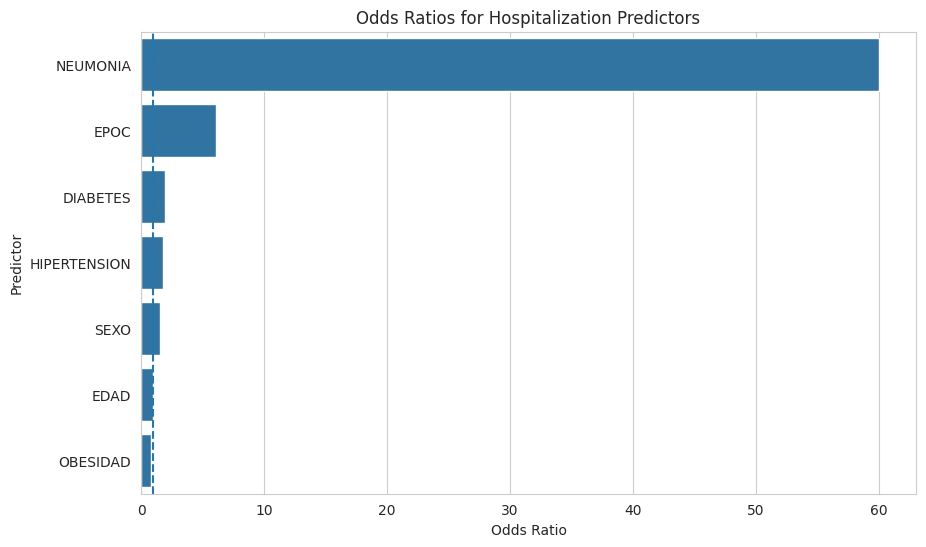

In [ ]:
# Extract logistic regression coefficients
coefficients = log_model.coef_[0]

# Convert coefficients into odds ratios
odds_ratios = np.exp(coefficients)

# Create odds ratio results table
odds_ratio_df = pd.DataFrame({
    "Predictor": X.columns,
    "Coefficient": coefficients,
    "Odds Ratio": odds_ratios
})

# Sort odds ratios from highest to lowest
odds_ratio_df = odds_ratio_df.sort_values(by="Odds Ratio", ascending=False)

# Display odds ratio table
print("\nOdds Ratios for Baseline Logistic Regression:")
print(odds_ratio_df)

# Create odds ratio plot
plt.figure(figsize=(10,6))

# Plot odds ratios
sns.barplot(
    x="Odds Ratio",
    y="Predictor",
    data=odds_ratio_df
)

# Add reference line at odds ratio = 1
plt.axvline(1, linestyle="--")

# Add title and labels
plt.title("Odds Ratios for Hospitalization Predictors")
plt.xlabel("Odds Ratio")
plt.ylabel("Predictor")

# Show plot
plt.show()

<FONT SIZE=5 COLOR="orange">
Los pacientes con neumonía tienen aproximadamente 60 veces mayores posibilidades relativas de ser hospitalizados que los pacientes sin neumonía, manteniendo constantes las demás variables del modelo.</FONT>
</H3>

<FONT SIZE=5 COLOR="F6B1F0"><b>Odds Ratio Interpretation:</b>
<br>
The logistic regression odds ratios show that pneumonia was the strongest factor associated with hospitalization, with an odds ratio of approximately 60.05. This means that patients with pneumonia had about 60 times higher odds of hospitalization than patients without pneumonia, holding the other predictors constant.
<br><br>
COPD was the second strongest predictor, with an odds ratio of approximately 6.10. Diabetes and hypertension were also associated with increased hospitalization odds, with odds ratios of approximately 1.96 and 1.81, respectively.
<br><br>
These results support the epidemiological interpretation of the project: clinical complications and chronic comorbidities are strongly associated with hospitalization status. The odds ratios are not percentages; they represent relative changes in hospitalization odds.
</FONT>

<FONT SIZE=6 COLOR="orange">Conclusion and Public Health Implications</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section summarizes the main findings of the project and discusses their relevance for public health surveillance, hospitalization risk identification, and future model refinement.
</FONT>

<FONT SIZE=5 COLOR="F6B1F0"><b>Conclusion:</b>
<br>
This project analyzed Mexico’s updated respiratory surveillance dataset to identify factors associated with hospitalization. The analysis showed that hospitalization was strongly associated with clinical and comorbidity-related factors, especially pneumonia, COPD, diabetes, and hypertension.
<br><br>
Logistic regression provided an interpretable epidemiological baseline through odds ratios. Pneumonia was the strongest predictor, followed by COPD, diabetes, and hypertension. These findings support the clinical relevance of the selected predictors.
<br><br>
The modeling workflow was refined to address recall, which is especially important in healthcare-related prediction tasks. Threshold tuning increased recall substantially, while Random Forest provided the best overall predictive balance. This combination supports both interpretability and improved predictive performance.
<br><br>
From a public health perspective, these results may support earlier identification of high-risk respiratory patients and help inform surveillance dashboards or hospitalization preparedness strategies. Future work should focus on external validation, calibration, and operational testing before any real-world deployment.
</FONT>

<FONT SIZE=5 COLOR="orange">COPD, equivalent to EPOC in the original Mexican dataset, refers to chronic obstructive pulmonary disease.</FONT>
<br>
<FONT SIZE=5 COLOR="33FF5B">EPOC = Enfermedad Pulmonar Obstructiva Crónica</FONT>

<FONT SIZE=6 COLOR="orange">Limitations</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section summarizes the main limitations of the analysis, including the use of secondary surveillance data, special coded values, lack of external validation, and the need for caution before operational deployment.
</FONT>

<FONT SIZE=5 COLOR="F6B1F0"><b>Limitations:</b>
<br>
This analysis is based on secondary surveillance data, so the results depend on the quality, completeness, and consistency of the original reporting system.
<br><br>
The dataset included special coded values such as 97, 98, and 99, which required careful recoding before analysis. Although these values were handled systematically, they still reflect limitations in the original data collection process.
<br><br>
The models were evaluated using an internal train-test split, but no external validation was performed. Therefore, the results should be interpreted as analytical and exploratory rather than as evidence of operational readiness.
<br><br>
Finally, the models identify associations with hospitalization, not causal relationships. Before any use in real-world public health or clinical workflows, additional validation, calibration, and institutional review would be necessary.
</FONT>

<FONT SIZE=6 COLOR="orange">Future Work</FONT>
<br><br>

<FONT SIZE=5 COLOR="00B5FE">
This section outlines recommended next steps for strengthening the analysis, including external validation, model calibration, additional feature engineering, and potential integration into public health surveillance workflows.
</FONT>

<FONT SIZE=5 COLOR="F6B1F0"><b>Future Work:</b>
<br>
Future work should focus on validating the models with additional surveillance data from later reporting periods or from external sources. This would help determine whether the observed performance is stable beyond the current dataset.
<br><br>
Model calibration should also be evaluated to ensure that predicted hospitalization probabilities are reliable and not only useful for classification. This is especially important if the model were ever considered for surveillance dashboards or operational decision support.
<br><br>
Additional feature engineering may improve performance, including temporal variables, institutional reporting patterns, regional indicators, and clinically relevant interactions among comorbidities.
<br><br>
Finally, any potential public health implementation should be treated as a decision-support tool, not an automated clinical decision system. The model would require external validation, calibration, monitoring, and institutional review before real-world deployment.
</FONT>